# Does style-aware prompting help CLIP across a real (non-artistic) domain shift?

This notebook is a small experiment, not a new method. Prof. Talemi's Style-Pro paper shows that giving CLIP a prompt that names the visual style ("a sketch of a dog" instead of "a photo of a dog") helps it generalize across PACS-style domains (photo, sketch, cartoon, painting). That result is already well established in the CLIP domain-generalization literature (Domain Prompt Learning, PromptStyler, DAPT all show the same thing on PACS/VLCS/OfficeHome).

So instead of repeating that on PACS, this notebook asks a narrower and more honest question:

**Does the same trick (naming the domain in the text prompt) still help when the domain shift is a sensor difference (RGB vs thermal/infrared) rather than an artistic style difference?**

This matters for the kind of applications her lab actually works on (wildfire monitoring, remote sensing, low-light biometrics), where the domain gap is physical, not stylistic. If domain-aware prompting doesn't transfer to this setting, that's a genuinely useful negative result, not a failure.

## Motivation

Vision-language models like CLIP are usually evaluated with a generic prompt template such as "a photo of a {class}". That wording matches ordinary photos well, but it stops matching the input once the sensor changes, for example when the image is thermal instead of RGB. This notebook checks whether a small, free fix (just naming the domain in the prompt, no training) closes any of that gap.

## Research question

Can simple domain-aware prompts improve zero-shot CLIP classification under an RGB to thermal domain shift, without changing the model at all?

## How this is different from Style-Pro

Worth being upfront about, since the idea traces back to that paper. Based on the published description of Style-Pro:

| | Style-Pro | This notebook |
|---|---|---|
| Prompts | learned during training | hand-written, fixed |
| What it is | a new adaptation method | an empirical check of an existing idea in a new setting |
| Domain shift tested | artistic style (photo, sketch, cartoon, painting) | sensor type (RGB vs thermal) |
| Training required | yes | no, zero-shot only |

So this isn't proposing anything new. It's asking whether something that already works for style shifts still works for a sensor shift.

**Dataset:** Teledyne FLIR ADAS Thermal Dataset v2 (free, Kaggle: `samdazel/teledyne-flir-adas-thermal-dataset-v2`). Time-synced RGB and thermal image pairs from a vehicle-mounted camera rig, COCO-annotated, with shared object categories (person, car, bike, truck, etc). You need to accept FLIR's dataset terms once on the Kaggle dataset page before it will attach to a notebook.

**Model:** CLIP ViT-B/32 (`openai/clip-vit-base-patch32` via `transformers`), used zero-shot. No training, no fine-tuning.

**What this notebook does, in order:**
1. finds the dataset files and parses the COCO annotations for both domains
2. crops objects out of the full frames using the bounding boxes, capped per class
3. runs CLIP zero-shot classification under four prompt conditions: bare class name, generic ("a photo of a..."), domain-aware, and a domain-aware ensemble of several phrasings
4. computes accuracy, balanced accuracy, macro F1, and expected calibration error (ECE) for every domain x condition combination
5. runs a McNemar test and a bootstrap confidence interval on the accuracy difference between generic and domain-aware prompts, per domain
6. saves all figures and metric tables to `/kaggle/working/results/`

Turn on the internet toggle in notebook settings (needed once, to download the CLIP weights from Hugging Face) and attach the dataset before running.


In [12]:
import os, json, glob, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

# every output this notebook produces goes under these folders, nothing is left loose in /kaggle/working
RESULTS_DIR = "/kaggle/working/results"
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
METRICS_DIR = os.path.join(RESULTS_DIR, "metrics")
CROPS_DIR = "/kaggle/working/crops"

for d in [RESULTS_DIR, FIG_DIR, METRICS_DIR, CROPS_DIR]:
    os.makedirs(d, exist_ok=True)

# classes we test on, must exist in the FLIR ADAS category list and show up in both domains
# classes we test on, these need to match the exact category names in the dataset's coco.json
# and show up with enough samples in both domains. FLIR ADAS uses "bike" not "bicycle", and
# categories like dog are too rare in dashcam footage to be usable, check the category count
# cell below before changing this
KEEP_CLASSES = ["person", "car", "bike", "truck"]
MAX_PER_CLASS_PER_DOMAIN = 150   # keep runtime sane on the free Kaggle GPU quota
MIN_BOX_SIDE_PX = 20             # drop tiny/unusable boxes
PAD_FRAC = 0.15                  # pad the crop a bit around the box so CLIP sees some context
BATCH_SIZE = 32


device: cuda


## 1. Find the dataset on disk

The exact folder names inside a Kaggle dataset can shift a little between uploads, so instead of hardcoding a path this cell searches everything under `/kaggle/input` for `coco.json` files and sorts each one into "thermal" or "rgb" based on the folder name. If your dataset has a different layout you'll see that in the printed list below and can adjust `THERMAL_HINTS` / `RGB_HINTS`.

In [13]:
THERMAL_HINTS = ["thermal", "ir_", "infrared", "lwir"]
RGB_HINTS = ["rgb", "visible", "color"]

all_coco_files = glob.glob("/kaggle/input/**/coco.json", recursive=True)
print(f"found {len(all_coco_files)} coco.json files")
for p in all_coco_files:
    print(" ", p)

def classify_domain(path):
    # only look at the folder that directly holds coco.json, not the whole path,
    # because the dataset's root folder name itself contains "thermal"
    # (e.g. "teledyne-flir-adas-thermal-dataset-v2"), which would otherwise
    # misclassify the rgb coco.json too
    folder_name = os.path.basename(os.path.dirname(path)).lower()
    if any(h in folder_name for h in RGB_HINTS):
        return "rgb"
    if any(h in folder_name for h in THERMAL_HINTS):
        return "thermal"
    return None

domain_to_coco = {}
for p in all_coco_files:
    dom = classify_domain(p)
    if dom is None:
        continue
    is_train = "train" in os.path.basename(os.path.dirname(p)).lower()
    if dom not in domain_to_coco:
        domain_to_coco[dom] = p
    elif is_train and "train" not in os.path.basename(os.path.dirname(domain_to_coco[dom])).lower():
        # only replace the existing pick if this one is a train split and the current pick isn't
        domain_to_coco[dom] = p

assert "thermal" in domain_to_coco, "could not find a thermal coco.json, check the dataset is attached and check THERMAL_HINTS"
assert "rgb" in domain_to_coco, "could not find an rgb coco.json, check the dataset is attached and check RGB_HINTS"

print()
print("using:")
for dom, p in domain_to_coco.items():
    print(f"  {dom}: {p}")

# images normally sit in a sibling "data" folder next to coco.json, but this differs across uploads,
# so we discover it from the first image entry in the annotation file itself instead of guessing
def find_image_dir(coco_path):
    with open(coco_path) as f:
        coco = json.load(f)
    base_dir = os.path.dirname(coco_path)
    sample_name = coco["images"][0]["file_name"]
    candidates = [
        base_dir,
        os.path.join(base_dir, "data"),
        os.path.join(base_dir, "images"),
    ]
    for c in candidates:
        if os.path.exists(os.path.join(c, sample_name)):
            return c
    # last resort: search for the file under base_dir
    hits = glob.glob(os.path.join(base_dir, "**", sample_name), recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    raise FileNotFoundError(f"could not locate image files for {coco_path}, sample file was {sample_name}")

domain_to_imgdir = {dom: find_image_dir(p) for dom, p in domain_to_coco.items()}
print()
print("image directories:")
for dom, d in domain_to_imgdir.items():
    print(f"  {dom}: {d}")


found 6 coco.json files
  /kaggle/input/datasets/samdazel/teledyne-flir-adas-thermal-dataset-v2/FLIR_ADAS_v2/video_rgb_test/coco.json
  /kaggle/input/datasets/samdazel/teledyne-flir-adas-thermal-dataset-v2/FLIR_ADAS_v2/images_thermal_train/coco.json
  /kaggle/input/datasets/samdazel/teledyne-flir-adas-thermal-dataset-v2/FLIR_ADAS_v2/images_rgb_val/coco.json
  /kaggle/input/datasets/samdazel/teledyne-flir-adas-thermal-dataset-v2/FLIR_ADAS_v2/images_thermal_val/coco.json
  /kaggle/input/datasets/samdazel/teledyne-flir-adas-thermal-dataset-v2/FLIR_ADAS_v2/images_rgb_train/coco.json
  /kaggle/input/datasets/samdazel/teledyne-flir-adas-thermal-dataset-v2/FLIR_ADAS_v2/video_thermal_test/coco.json

using:
  rgb: /kaggle/input/datasets/samdazel/teledyne-flir-adas-thermal-dataset-v2/FLIR_ADAS_v2/images_rgb_train/coco.json
  thermal: /kaggle/input/datasets/samdazel/teledyne-flir-adas-thermal-dataset-v2/FLIR_ADAS_v2/images_thermal_train/coco.json

image directories:
  rgb: /kaggle/input/datasets/

### Check what categories actually exist before picking classes

`KEEP_CLASSES` up in the config cell is a guess at reasonable class names. Datasets don't always use the word you expect ("bike" instead of "bicycle" is a common one), and some categories barely show up at all in a given dataset. This cell counts every category in both domains so you can see the real names and real counts before committing to which four to use. If anything in `KEEP_CLASSES` shows 0 or a very small number here, go back to the config cell, fix the spelling or swap it for something with real support in both domains, then rerun from there.

In [14]:
def category_counts(coco_path):
    with open(coco_path) as f:
        coco = json.load(f)
    cat_id_to_name = {c["id"]: c["name"] for c in coco["categories"]}
    counts = {}
    for ann in coco["annotations"]:
        name = cat_id_to_name.get(ann["category_id"], "unknown")
        counts[name] = counts.get(name, 0) + 1
    return counts

rgb_counts = category_counts(domain_to_coco["rgb"])
thermal_counts = category_counts(domain_to_coco["thermal"])
all_cats = sorted(set(rgb_counts) | set(thermal_counts))

cat_df = pd.DataFrame({
    "rgb_count": [rgb_counts.get(c, 0) for c in all_cats],
    "thermal_count": [thermal_counts.get(c, 0) for c in all_cats],
}, index=all_cats).sort_values("rgb_count", ascending=False)
print(cat_df)

print()
for cls in KEEP_CLASSES:
    r, t = rgb_counts.get(cls, 0), thermal_counts.get(cls, 0)
    flag = "  <-- missing or very low, pick a different class" if min(r, t) < 30 else ""
    print(f"KEEP_CLASSES check: {cls!r}  rgb={r}  thermal={t}{flag}")


               rgb_count  thermal_count
car                71281          73623
person             35007          50478
sign               29531          20770
light              18640          16198
bike                7560           7237
bus                 1879           2245
motor               1837           1116
truck               1251            829
hydrant              990           1095
other vehicle        698           1373
skateboard           412             29
scooter               41             15
stroller              38             15
train                  9              5
dog                    0              4
deer                   0              8

KEEP_CLASSES check: 'person'  rgb=35007  thermal=50478
KEEP_CLASSES check: 'car'  rgb=71281  thermal=73623
KEEP_CLASSES check: 'bike'  rgb=7560  thermal=7237
KEEP_CLASSES check: 'truck'  rgb=1251  thermal=829


## 2. Parse annotations and crop out objects

We pull crops out of the full frames using the bounding boxes, pad each box a little, clip to the image bounds, and cap how many crops we keep per class so both domains end up with comparable and manageable sample sizes. Crops are saved to disk under `crops/<domain>/<class>/` as we go, so if the notebook is interrupted partway you can see exactly how far it got.

In [15]:
def load_crops_from_coco(coco_path, img_dir, keep_classes, max_per_class, min_box_side, pad_frac, save_dir):
    with open(coco_path) as f:
        coco = json.load(f)

    cat_id_to_name = {c["id"]: c["name"] for c in coco["categories"]}
    img_id_to_info = {im["id"]: im for im in coco["images"]}

    per_class_count = {c: 0 for c in keep_classes}
    records = []
    skipped_missing_file = 0
    skipped_bad_box = 0

    for cls in keep_classes:
        os.makedirs(os.path.join(save_dir, cls), exist_ok=True)

    for ann in coco["annotations"]:
        cls_name = cat_id_to_name.get(ann["category_id"])
        if cls_name not in keep_classes:
            continue
        if per_class_count[cls_name] >= max_per_class:
            continue

        img_info = img_id_to_info.get(ann["image_id"])
        if img_info is None:
            continue

        img_path = os.path.join(img_dir, img_info["file_name"])
        if not os.path.exists(img_path):
            skipped_missing_file += 1
            continue

        x, y, w, h = ann["bbox"]
        if w < min_box_side or h < min_box_side:
            skipped_bad_box += 1
            continue

        pad_w, pad_h = w * pad_frac, h * pad_frac
        x0 = max(0, x - pad_w)
        y0 = max(0, y - pad_h)
        x1 = min(img_info["width"], x + w + pad_w)
        y1 = min(img_info["height"], y + h + pad_h)
        if x1 <= x0 or y1 <= y0:
            skipped_bad_box += 1
            continue

        try:
            with Image.open(img_path) as im:
                im = im.convert("RGB")
                crop = im.crop((x0, y0, x1, y1))
                crop.load()
        except Exception:
            skipped_missing_file += 1
            continue

        idx = per_class_count[cls_name]
        out_path = os.path.join(save_dir, cls_name, f"{idx:04d}.jpg")
        crop.save(out_path, quality=92)

        bbox_area_frac = (w * h) / (img_info["width"] * img_info["height"])
        records.append({"class_name": cls_name, "path": out_path, "bbox_area_frac": bbox_area_frac})
        per_class_count[cls_name] += 1

    return pd.DataFrame(records), per_class_count, skipped_missing_file, skipped_bad_box


all_records = []
for dom in ["rgb", "thermal"]:
    save_dir = os.path.join(CROPS_DIR, dom)
    df, counts, skip_missing, skip_bad = load_crops_from_coco(
        domain_to_coco[dom], domain_to_imgdir[dom], KEEP_CLASSES,
        MAX_PER_CLASS_PER_DOMAIN, MIN_BOX_SIDE_PX, PAD_FRAC, save_dir,
    )
    df["domain"] = dom
    all_records.append(df)
    print(f"{dom:8s} counts: {counts}  (skipped missing files: {skip_missing}, skipped tiny/bad boxes: {skip_bad})")

crops_df = pd.concat(all_records, ignore_index=True)
print()
print("total crops:", len(crops_df))
crops_df.to_csv(os.path.join(METRICS_DIR, "crop_manifest.csv"), index=False)

# sanity check: make sure we actually have samples for every class in every domain before going further,
# a class with zero samples in one domain would silently break the per-class metrics later
pivot_check = crops_df.groupby(["domain", "class_name"]).size().unstack(fill_value=0)
print(pivot_check)
assert not (pivot_check == 0).any().any(), (
    "one or more classes have zero crops in a domain, drop that class from KEEP_CLASSES or raise MAX_PER_CLASS_PER_DOMAIN / lower MIN_BOX_SIDE_PX"
)


rgb      counts: {'person': 150, 'car': 150, 'bike': 150, 'truck': 150}  (skipped missing files: 0, skipped tiny/bad boxes: 39)
thermal  counts: {'person': 150, 'car': 150, 'bike': 150, 'truck': 150}  (skipped missing files: 0, skipped tiny/bad boxes: 1224)

total crops: 1200
class_name  bike  car  person  truck
domain                              
rgb          150  150     150    150
thermal      150  150     150    150


## 3. Load CLIP and set up prompt conditions

Four conditions, from weakest to most informative:

- **bare** — just the class name, no template at all (the weakest CLIP baseline from the original paper)
- **generic** — `"a photo of a {class}"`, the standard CLIP default template, used the same way regardless of domain
- **domain_aware** — a single template that names the actual domain, e.g. `"a thermal camera image of a {class}"` for the thermal set
- **domain_aware_ensemble** — several differently worded domain-aware templates per class, averaged together (this is the ensembling idea, cheap and doesn't need training)

For the RGB domain, "generic" and "domain_aware" are nearly the same wording on purpose, since a normal photo mostly matches what "a photo of" already implies. The real test is the thermal domain, where the visual content genuinely doesn't look like what CLIP calls a "photo."

Why each one is here:
- **bare** exists as the floor, whatever CLIP can do with basically no prompt at all
- **generic** is the standard CLIP baseline everyone uses by default, this is what most people would ship without thinking about it
- **domain_aware** is the actual test, does naming the sensor type help
- **domain_aware_ensemble** checks whether averaging a few different phrasings makes the prediction more stable than betting on one exact wording


In [16]:
from transformers import CLIPModel, CLIPProcessor

MODEL_NAME = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()
processor = CLIPProcessor.from_pretrained(MODEL_NAME)

PROMPT_TEMPLATES = {
    "bare": {
        "rgb": ["{cls}"],
        "thermal": ["{cls}"],
    },
    "generic": {
        "rgb": ["a photo of a {cls}"],
        "thermal": ["a photo of a {cls}"],
    },
    "domain_aware": {
        "rgb": ["a color photograph of a {cls}"],
        "thermal": ["a thermal camera image of a {cls}"],
    },
    "domain_aware_ensemble": {
        "rgb": [
            "a color photograph of a {cls}",
            "a daytime photo of a {cls}",
            "a photo of a {cls} taken with a regular camera",
        ],
        "thermal": [
            "a thermal camera image of a {cls}",
            "an infrared heat signature of a {cls}",
            "a black and white thermal photo of a {cls}",
        ],
    },
}

print("conditions:", list(PROMPT_TEMPLATES.keys()))


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


conditions: ['bare', 'generic', 'domain_aware', 'domain_aware_ensemble']


In [30]:
def _extract_embeds(output, embeds_attr):
    """
    Different transformers versions return different things here: some return a plain
    tensor, some return a ModelOutput object with an image_embeds/text_embeds attribute,
    some fall back to pooler_output. This handles all three so the notebook doesn't break
    on a version difference.
    """
    if isinstance(output, torch.Tensor):
        return output
    if hasattr(output, embeds_attr) and getattr(output, embeds_attr) is not None:
        return getattr(output, embeds_attr)
    if hasattr(output, "pooler_output") and output.pooler_output is not None:
        return output.pooler_output
    raise AttributeError(
        f"could not find a tensor, '{embeds_attr}', or 'pooler_output' on the model output "
        f"(got type {type(output)}), check your transformers version"
    )


@torch.no_grad()
def encode_texts(prompts):
    inputs = processor(text=prompts, return_tensors="pt", padding=True).to(DEVICE)
    out = model.get_text_features(**inputs)
    feats = _extract_embeds(out, "text_embeds")
    feats = F.normalize(feats, dim=-1)
    return feats

@torch.no_grad()
def build_class_text_embeddings(condition, domain, classes):
    """one embedding per class: template(s) filled in, encoded, averaged, renormalized"""
    class_embs = []
    for cls in classes:
        templates = PROMPT_TEMPLATES[condition][domain]
        prompts = [t.format(cls=cls) for t in templates]
        feats = encode_texts(prompts)          # (n_templates, dim)
        mean_feat = feats.mean(dim=0)
        mean_feat = F.normalize(mean_feat, dim=0)   # must renormalize after averaging, cosine sim assumes unit vectors
        class_embs.append(mean_feat)
    return torch.stack(class_embs, dim=0)       # (n_classes, dim)


@torch.no_grad()
def encode_images(paths, batch_size=BATCH_SIZE):
    all_feats = []
    for i in range(0, len(paths), batch_size):
        batch_paths = paths[i:i + batch_size]
        imgs = [Image.open(p).convert("RGB") for p in batch_paths]
        inputs = processor(images=imgs, return_tensors="pt").to(DEVICE)
        out = model.get_image_features(**inputs)
        feats = _extract_embeds(out, "image_embeds")
        feats = F.normalize(feats, dim=-1)
        all_feats.append(feats.cpu())
    return torch.cat(all_feats, dim=0)


## 4. Run zero-shot classification

We encode every crop's image embedding once per domain (that part doesn't depend on the prompt condition, so we don't redo it four times), then for each condition we build the class text embeddings and classify.

In [18]:
results_rows = []
image_embeddings_cache = {}   # domain -> (paths, tensor) so we can reuse for the embedding plot later

for dom in ["rgb", "thermal"]:
    dom_df = crops_df[crops_df["domain"] == dom].reset_index(drop=True)
    paths = dom_df["path"].tolist()
    true_classes = dom_df["class_name"].tolist()
    true_idx = np.array([KEEP_CLASSES.index(c) for c in true_classes])
    bbox_area_fracs = dom_df["bbox_area_frac"].tolist()

    print(f"encoding {len(paths)} images for domain={dom} ...")
    img_embs = encode_images(paths)
    image_embeddings_cache[dom] = (dom_df, img_embs)

    for condition in PROMPT_TEMPLATES:
        text_embs = build_class_text_embeddings(condition, dom, KEEP_CLASSES).cpu()
        logit_scale = model.logit_scale.exp().item()
        logits = logit_scale * (img_embs @ text_embs.T)
        probs = F.softmax(logits, dim=-1)
        pred_idx = probs.argmax(dim=-1).numpy()
        conf = probs.max(dim=-1).values.numpy()

        for i in range(len(paths)):
            results_rows.append({
                "domain": dom,
                "condition": condition,
                "true_class": true_classes[i],
                "true_idx": int(true_idx[i]),
                "pred_class": KEEP_CLASSES[pred_idx[i]],
                "pred_idx": int(pred_idx[i]),
                "confidence": float(conf[i]),
                "correct": bool(pred_idx[i] == true_idx[i]),
                "path": paths[i],
                "bbox_area_frac": bbox_area_fracs[i],
            })
    print(f"  done: {dom}")

results_df = pd.DataFrame(results_rows)
results_df.to_csv(os.path.join(METRICS_DIR, "predictions.csv"), index=False)
print()
print("total predictions logged:", len(results_df))
results_df.head()


encoding 600 images for domain=rgb ...
  done: rgb
encoding 600 images for domain=thermal ...
  done: thermal

total predictions logged: 4800


,domain,condition,true_class,true_idx,pred_class,pred_idx,confidence,correct,path,bbox_area_frac
0,rgb,bare,car,1,truck,3,0.483593,False,/kaggle/working/crops/rgb/car/0000.jpg,0.002268
1,rgb,bare,car,1,car,1,0.805785,True,/kaggle/working/crops/rgb/car/0001.jpg,0.010806
2,rgb,bare,car,1,person,0,0.530050,False,/kaggle/working/crops/rgb/car/0002.jpg,0.001485
3,rgb,bare,car,1,person,0,0.412950,False,/kaggle/working/crops/rgb/car/0003.jpg,0.000316
4,rgb,bare,car,1,person,0,0.756479,False,/kaggle/working/crops/rgb/car/0004.jpg,0.002457


## 5. Metrics: accuracy, balanced accuracy, macro F1, calibration

Balanced accuracy and macro F1 matter here because the class counts across the four categories aren't perfectly even (person and car dominate in ADAS-style footage), so plain accuracy alone could hide a model that just always guesses the majority class. Expected Calibration Error (ECE) checks whether CLIP's confidence scores are trustworthy, not just whether the top guess is right; a model can be accurate but badly overconfident, which matters if this were ever used to flag things automatically.

In [19]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix

def expected_calibration_error(confidences, correct, n_bins=10):
    confidences = np.asarray(confidences)
    correct = np.asarray(correct).astype(float)
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    n = len(confidences)
    ece = 0.0
    bin_rows = []
    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        mask = (confidences >= lo) & (confidences <= hi) if i == n_bins - 1 else (confidences >= lo) & (confidences < hi)
        cnt = int(mask.sum())
        if cnt == 0:
            bin_rows.append({"bin_lo": lo, "bin_hi": hi, "count": 0, "acc": np.nan, "conf": np.nan})
            continue
        bin_acc = correct[mask].mean()
        bin_conf = confidences[mask].mean()
        ece += (cnt / n) * abs(bin_acc - bin_conf)
        bin_rows.append({"bin_lo": lo, "bin_hi": hi, "count": cnt, "acc": bin_acc, "conf": bin_conf})
    return ece, pd.DataFrame(bin_rows)


metric_rows = []
for (dom, cond), g in results_df.groupby(["domain", "condition"]):
    acc = accuracy_score(g["true_idx"], g["pred_idx"])
    bal_acc = balanced_accuracy_score(g["true_idx"], g["pred_idx"])
    macro_f1 = f1_score(g["true_idx"], g["pred_idx"], average="macro", zero_division=0)
    ece, _ = expected_calibration_error(g["confidence"].values, g["correct"].values)
    mean_conf = g["confidence"].mean()
    metric_rows.append({
        "domain": dom, "condition": cond, "n": len(g),
        "accuracy": acc, "balanced_accuracy": bal_acc, "macro_f1": macro_f1,
        "ece": ece, "mean_confidence": mean_conf,
    })

metrics_df = pd.DataFrame(metric_rows).sort_values(["domain", "condition"]).reset_index(drop=True)
metrics_df.to_csv(os.path.join(METRICS_DIR, "summary_metrics.csv"), index=False)
metrics_df


,domain,condition,n,accuracy,balanced_accuracy,macro_f1,ece,mean_confidence
0,rgb,bare,600,0.670000,0.670000,0.676350,0.044923,0.678635
1,rgb,domain_aware,600,0.706667,0.706667,0.707328,0.022763,0.713501
2,rgb,domain_aware_ensemble,600,0.695000,0.695000,0.697465,0.067931,0.735675
3,rgb,generic,600,0.690000,0.690000,0.696441,0.064613,0.737255
4,thermal,bare,600,0.445000,0.445000,0.388862,0.253128,0.698128
5,thermal,domain_aware,600,0.506667,0.506667,0.454103,0.092094,0.597351
6,thermal,domain_aware_ensemble,600,0.516667,0.516667,0.466635,0.104000,0.620667
7,thermal,generic,600,0.440000,0.440000,0.375395,0.307617,0.747617


## 6. Is the domain-aware gain real, or noise?

Accuracy differences of a couple of points on a few hundred images can easily be noise. We check this two ways for `generic` vs `domain_aware` on each domain: a McNemar test (uses only the crops where the two conditions disagreed on the same image, which is the correct paired test here since it's the same images and same model, just different prompts) and a bootstrap confidence interval on the accuracy difference.

In [20]:
from statsmodels.stats.contingency_tables import mcnemar
from scipy.stats import bootstrap

def paired_significance(results_df, domain, cond_a, cond_b, n_boot=2000, seed=0):
    a = results_df[(results_df.domain == domain) & (results_df.condition == cond_a)].sort_values("path").reset_index(drop=True)
    b = results_df[(results_df.domain == domain) & (results_df.condition == cond_b)].sort_values("path").reset_index(drop=True)
    assert (a["path"].values == b["path"].values).all(), "prediction rows are not aligned by image, check the sort/merge"

    a_correct = a["correct"].values
    b_correct = b["correct"].values

    # McNemar's table only needs the disagreement counts
    only_a_correct = int(((a_correct == True) & (b_correct == False)).sum())
    only_b_correct = int(((a_correct == False) & (b_correct == True)).sum())
    table = [[0, only_a_correct], [only_b_correct, 0]]
    exact = (only_a_correct + only_b_correct) < 25
    mres = mcnemar(table, exact=exact)

    n = len(a_correct)
    def acc_diff(idx):
        idx = idx.astype(int)
        return b_correct[idx].mean() - a_correct[idx].mean()

    boot = bootstrap((np.arange(n),), acc_diff, n_resamples=n_boot, method="basic", random_state=seed)

    return {
        "domain": domain, "cond_a": cond_a, "cond_b": cond_b, "n": n,
        "acc_a": a_correct.mean(), "acc_b": b_correct.mean(),
        "acc_diff": b_correct.mean() - a_correct.mean(),
        "mcnemar_b": only_a_correct, "mcnemar_c": only_b_correct,
        "mcnemar_p": float(mres.pvalue),
        "bootstrap_ci_low": float(boot.confidence_interval.low),
        "bootstrap_ci_high": float(boot.confidence_interval.high),
    }

sig_rows = []
for dom in ["rgb", "thermal"]:
    sig_rows.append(paired_significance(results_df, dom, "generic", "domain_aware"))
    sig_rows.append(paired_significance(results_df, dom, "generic", "domain_aware_ensemble"))

sig_df = pd.DataFrame(sig_rows)
sig_df.to_csv(os.path.join(METRICS_DIR, "significance_tests.csv"), index=False)
sig_df


,domain,cond_a,cond_b,n,acc_a,acc_b,acc_diff,mcnemar_b,mcnemar_c,mcnemar_p,bootstrap_ci_low,bootstrap_ci_high
0,rgb,generic,domain_aware,600,0.69,0.706667,0.016667,23,33,0.229102,-0.006708,0.041667
1,rgb,generic,domain_aware_ensemble,600,0.69,0.695000,0.005000,12,15,0.700311,-0.011667,0.021667
2,thermal,generic,domain_aware,600,0.44,0.506667,0.066667,41,81,0.000414,0.031667,0.101667
3,thermal,generic,domain_aware_ensemble,600,0.44,0.516667,0.076667,29,75,0.000010,0.043333,0.108333


## 7. Figures

Everything below is saved as a PNG into `results/figures/` as it's generated.

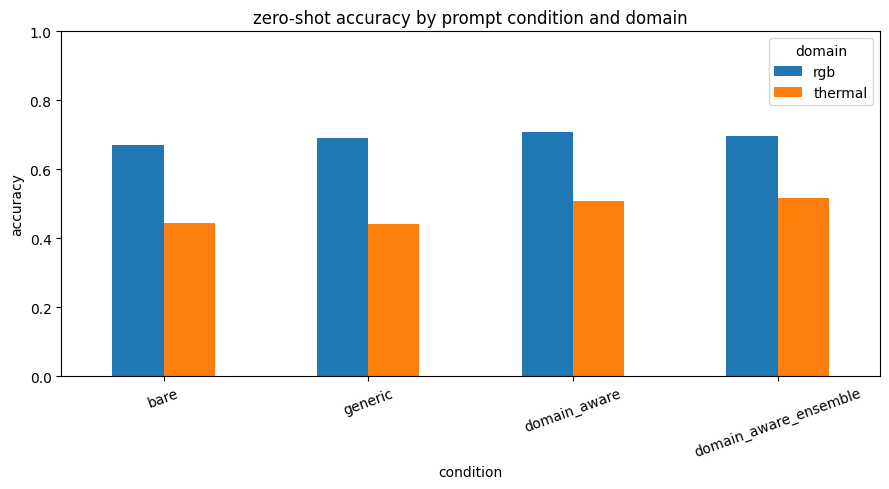

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
pivot = metrics_df.pivot(index="condition", columns="domain", values="accuracy")
pivot = pivot.reindex(["bare", "generic", "domain_aware", "domain_aware_ensemble"])
pivot.plot(kind="bar", ax=ax)
ax.set_ylabel("accuracy")
ax.set_title("zero-shot accuracy by prompt condition and domain")
ax.set_ylim(0, 1)
ax.legend(title="domain")
plt.xticks(rotation=20)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "accuracy_by_condition_domain.png"), dpi=150)
plt.show()


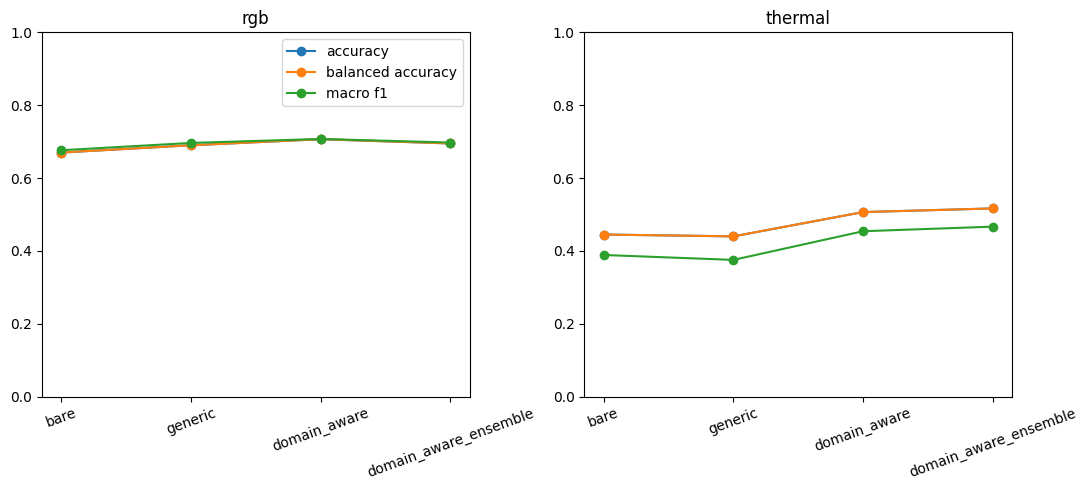

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, dom in zip(axes, ["rgb", "thermal"]):
    sub = metrics_df[metrics_df.domain == dom].set_index("condition").reindex(
        ["bare", "generic", "domain_aware", "domain_aware_ensemble"]
    )
    ax.plot(sub.index, sub["accuracy"], marker="o", label="accuracy")
    ax.plot(sub.index, sub["balanced_accuracy"], marker="o", label="balanced accuracy")
    ax.plot(sub.index, sub["macro_f1"], marker="o", label="macro f1")
    ax.set_title(dom)
    ax.set_ylim(0, 1)
    plt.setp(ax.get_xticklabels(), rotation=20)
axes[0].legend()
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "metric_breakdown_by_domain.png"), dpi=150)
plt.show()


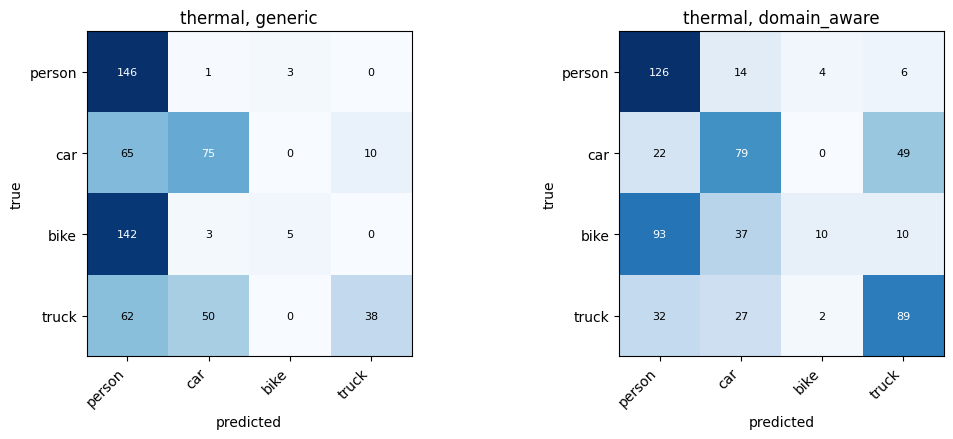

In [23]:
# confusion matrix, generic vs domain_aware, side by side, for the thermal domain specifically
# (thermal is where we expect the interesting behavior, rgb is mostly a sanity check)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, cond in zip(axes, ["generic", "domain_aware"]):
    sub = results_df[(results_df.domain == "thermal") & (results_df.condition == cond)]
    cm = confusion_matrix(sub["true_idx"], sub["pred_idx"], labels=list(range(len(KEEP_CLASSES))))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(KEEP_CLASSES))); ax.set_xticklabels(KEEP_CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(len(KEEP_CLASSES))); ax.set_yticklabels(KEEP_CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"thermal, {cond}")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "confusion_matrices_thermal.png"), dpi=150)
plt.show()


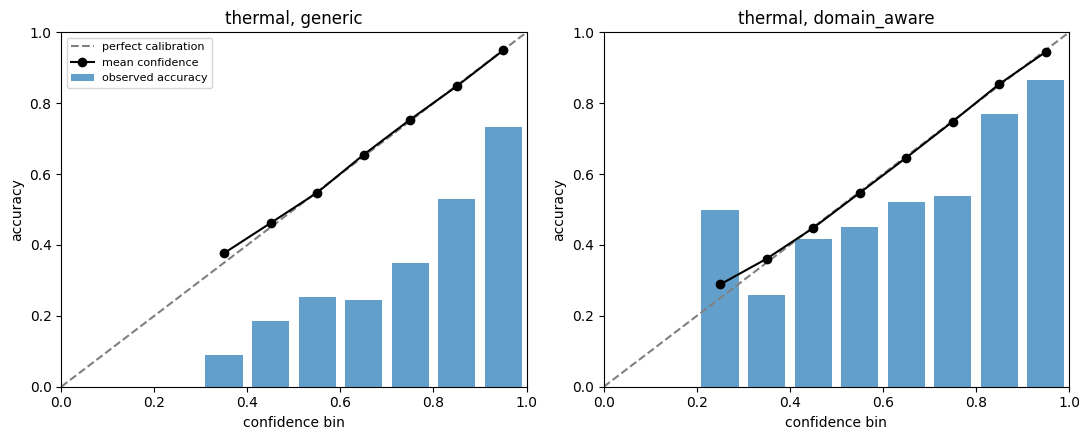

In [24]:
# reliability diagram: bins confidence into deciles and plots observed accuracy per bin against
# the diagonal (perfect calibration); a curve below the diagonal means the model is overconfident there
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, cond in zip(axes, ["generic", "domain_aware"]):
    sub = results_df[(results_df.domain == "thermal") & (results_df.condition == cond)]
    _, bins = expected_calibration_error(sub["confidence"].values, sub["correct"].values)
    bins_plot = bins.dropna()
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
    ax.bar((bins_plot["bin_lo"] + bins_plot["bin_hi"]) / 2, bins_plot["acc"],
           width=0.08, alpha=0.7, label="observed accuracy")
    ax.plot((bins_plot["bin_lo"] + bins_plot["bin_hi"]) / 2, bins_plot["conf"],
            marker="o", color="black", label="mean confidence")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title(f"thermal, {cond}")
    ax.set_xlabel("confidence bin"); ax.set_ylabel("accuracy")
axes[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "reliability_diagrams_thermal.png"), dpi=150)
plt.show()


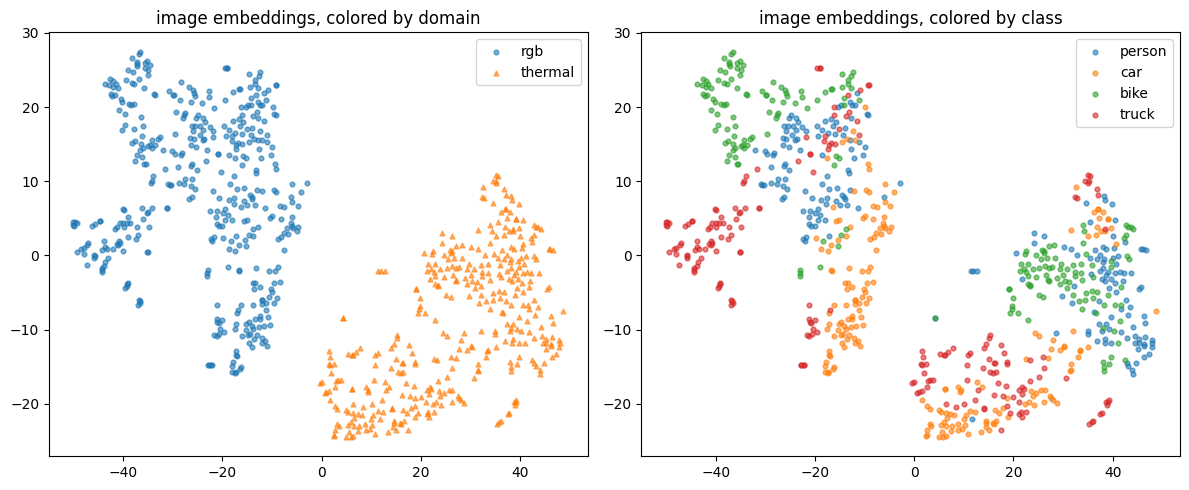

In [25]:
from sklearn.manifold import TSNE

# pull the raw image embeddings we already computed (not text embeddings), stack both domains,
# and project to 2D just to see visually whether rgb and thermal crops of the same class sit apart
rgb_df, rgb_embs = image_embeddings_cache["rgb"]
therm_df, therm_embs = image_embeddings_cache["thermal"]

combo_embs = torch.cat([rgb_embs, therm_embs], dim=0).numpy()
combo_domain = ["rgb"] * len(rgb_df) + ["thermal"] * len(therm_df)
combo_class = rgb_df["class_name"].tolist() + therm_df["class_name"].tolist()

# tsne on everything can be slow if MAX_PER_CLASS_PER_DOMAIN is large, subsample if needed
MAX_POINTS_FOR_TSNE = 800
idx = np.arange(len(combo_embs))
if len(idx) > MAX_POINTS_FOR_TSNE:
    idx = np.random.choice(idx, MAX_POINTS_FOR_TSNE, replace=False)

proj = TSNE(n_components=2, random_state=SEED, perplexity=30, init="pca").fit_transform(combo_embs[idx])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
domain_arr = np.array(combo_domain)[idx]
class_arr = np.array(combo_class)[idx]

for dom, marker in zip(["rgb", "thermal"], ["o", "^"]):
    m = domain_arr == dom
    axes[0].scatter(proj[m, 0], proj[m, 1], s=12, marker=marker, alpha=0.6, label=dom)
axes[0].legend(); axes[0].set_title("image embeddings, colored by domain")

for cls in KEEP_CLASSES:
    m = class_arr == cls
    axes[1].scatter(proj[m, 0], proj[m, 1], s=12, alpha=0.6, label=cls)
axes[1].legend(); axes[1].set_title("image embeddings, colored by class")

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "tsne_image_embeddings.png"), dpi=150)
plt.show()


## 8. A few wrong predictions

Numbers alone can hide what's actually going wrong. This pulls a handful of cases in the thermal domain where the generic prompt got it wrong, and shows what the domain-aware prompt did on the same image. Alongside each one, the object's box-area fraction is reported (how much of the frame the object actually takes up), since that's an objective thing we can check rather than a guess about why the model failed. A small box is a plausible factor in a miss, not a confirmed cause, it's just the one piece of hard evidence we have per image.

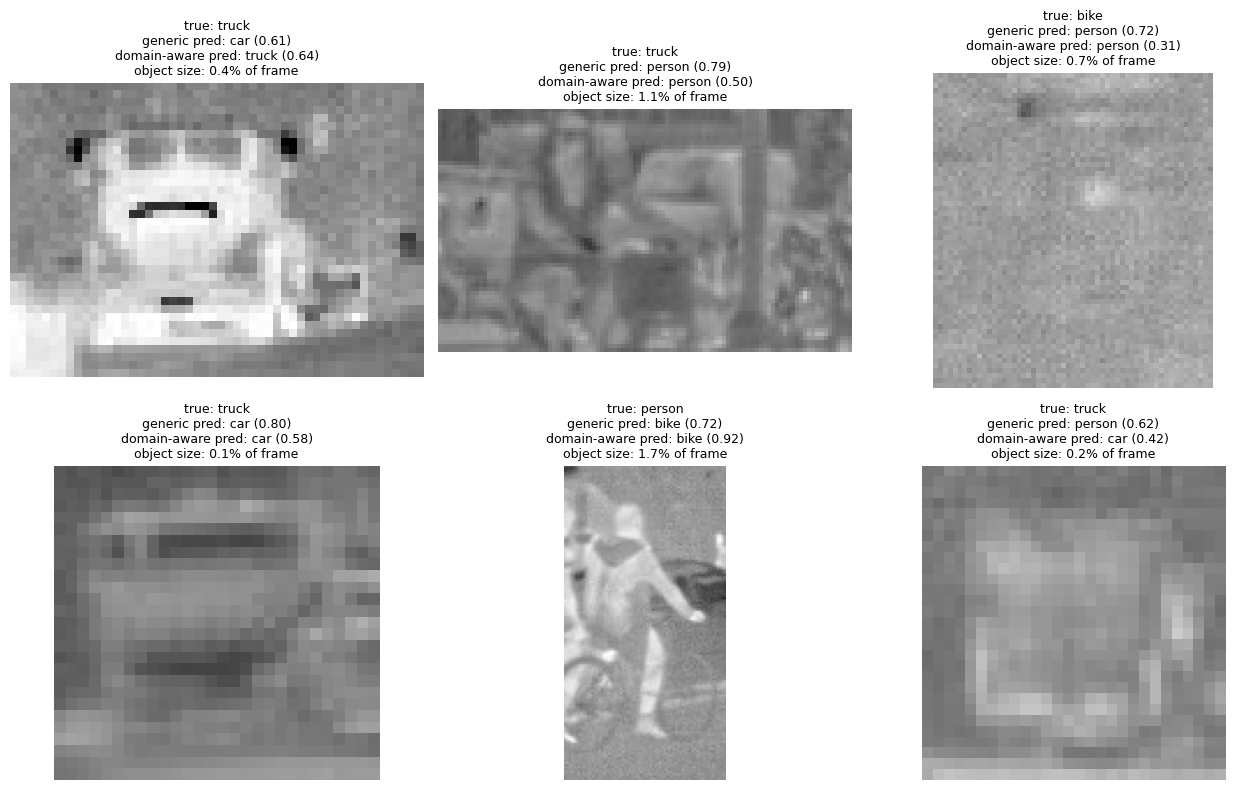

of all generic-prompt misses on thermal, 94% involve an object under 2% of the frame


In [26]:
thermal_generic = results_df[(results_df.domain == "thermal") & (results_df.condition == "generic")].set_index("path")
thermal_domain_aware = results_df[(results_df.domain == "thermal") & (results_df.condition == "domain_aware")].set_index("path")

wrong_paths = thermal_generic[thermal_generic["correct"] == False].index.tolist()
random.shuffle(wrong_paths)
sample_paths = wrong_paths[:6]

if len(sample_paths) == 0:
    print("no wrong predictions to show, generic prompt got everything right on thermal in this run")
else:
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    axes = axes.flatten()
    for ax, path in zip(axes, sample_paths):
        img = Image.open(path)
        ax.imshow(img)
        ax.axis("off")
        g = thermal_generic.loc[path]
        d = thermal_domain_aware.loc[path]
        area_pct = g["bbox_area_frac"] * 100
        title = (
            f"true: {g['true_class']}\n"
            f"generic pred: {g['pred_class']} ({g['confidence']:.2f})\n"
            f"domain-aware pred: {d['pred_class']} ({d['confidence']:.2f})\n"
            f"object size: {area_pct:.1f}% of frame"
        )
        ax.set_title(title, fontsize=9)
    for ax in axes[len(sample_paths):]:
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, "failure_cases_thermal.png"), dpi=150)
    plt.show()

    small_frac = (thermal_generic.loc[wrong_paths, "bbox_area_frac"] < 0.02).mean() if wrong_paths else float("nan")
    print(f"of all generic-prompt misses on thermal, {small_frac:.0%} involve an object under 2% of the frame")


## 9. Discussion

This reads the actual numbers from this run rather than assuming an outcome, so it says something different depending on whether domain-aware prompting helped, did nothing, or hurt.

In [27]:
def describe_effect(row):
    diff = row["acc_diff"]
    sig = row["mcnemar_p"] < 0.05
    if abs(diff) < 0.01:
        return "made essentially no difference"
    direction = "improved" if diff > 0 else "hurt"
    size = "a small but statistically distinguishable" if sig else "a small, not statistically significant"
    return f"{direction} accuracy by {abs(diff):.1%}, {size} change"

thermal_row = sig_df[(sig_df.domain == "thermal") & (sig_df.cond_b == "domain_aware")].iloc[0]
rgb_row = sig_df[(sig_df.domain == "rgb") & (sig_df.cond_b == "domain_aware")].iloc[0]

print("On the thermal domain, switching from a generic prompt to a domain-aware prompt")
print(f"  {describe_effect(thermal_row)}.")
print(f"  (McNemar p = {thermal_row['mcnemar_p']:.4f}, 95% bootstrap CI on the accuracy diff: "
      f"[{thermal_row['bootstrap_ci_low']:+.3f}, {thermal_row['bootstrap_ci_high']:+.3f}])")
print()
print("On the rgb domain, the same swap")
print(f"  {describe_effect(rgb_row)}.")
print(f"  (McNemar p = {rgb_row['mcnemar_p']:.4f}, 95% bootstrap CI: "
      f"[{rgb_row['bootstrap_ci_low']:+.3f}, {rgb_row['bootstrap_ci_high']:+.3f}])")
print()

if thermal_row["mcnemar_p"] < 0.05 and thermal_row["acc_diff"] > 0:
    print("Reading on this: the model's weights never change, only the wording of the text prompt does.")
    print("That the prediction still shifts means the image-text matching step is sensitive to how the")
    print("domain is described in words, and that sensitivity can be pointed in a useful direction without")
    print("any training. Whether that's worth doing in practice depends on how much accuracy is on the")
    print("table and how cheap it is to write a decent domain-aware prompt for a new sensor type.")
elif thermal_row["mcnemar_p"] >= 0.05:
    print("Reading on this: the difference on thermal images is not distinguishable from noise at this")
    print("sample size. That's a real finding, not a null result to bury. It suggests that for this dataset")
    print("and this model, simply naming the domain in the prompt is not doing the work Style-Pro's learned,")
    print("style-aware prompting does for artistic domain shifts. The gap between a sensor shift and a style")
    print("shift may just be bigger than a hand-written prompt can close on its own.")
else:
    print("Reading on this: domain-aware prompting made things worse here. A plausible explanation is that")
    print("the hand-written domain wording doesn't match how CLIP's training data described thermal imagery,")
    print("so the prompt change moved the text embedding in the wrong direction rather than the right one.")
    print("This is worth checking with different phrasings before concluding the underlying idea doesn't work.")


On the thermal domain, switching from a generic prompt to a domain-aware prompt
  improved accuracy by 6.7%, a small but statistically distinguishable change.
  (McNemar p = 0.0004, 95% bootstrap CI on the accuracy diff: [+0.032, +0.102])

On the rgb domain, the same swap
  improved accuracy by 1.7%, a small, not statistically significant change.
  (McNemar p = 0.2291, 95% bootstrap CI: [-0.007, +0.042])

Reading on this: the model's weights never change, only the wording of the text prompt does.
That the prediction still shifts means the image-text matching step is sensitive to how the
domain is described in words, and that sensitivity can be pointed in a useful direction without
any training. Whether that's worth doing in practice depends on how much accuracy is on the
table and how cheap it is to write a decent domain-aware prompt for a new sensor type.


## 10. Limitations

- Only one model was tested (CLIP ViT-B/32). SigLIP or a newer VLM might respond differently to the same prompts.
- Only one thermal dataset and one camera rig (FLIR ADAS, vehicle-mounted). Not a general claim about RGB-thermal shift everywhere.
- The domain-aware prompt wording was written by hand, not learned or searched over. A different phrasing could change the result in either direction.
- Class counts aren't perfectly balanced across domains, check the category count cell in section 1 for the actual numbers your run used, which is part of why balanced accuracy and macro F1 are reported alongside plain accuracy.
- No hyperparameter search, one seed for crop sampling. This is one run, not an average over several.


## 11. Conclusion

Also generated from the actual run, for the same reason as the discussion above.

In [28]:
print("CONCLUSION")
print("-" * 70)
if thermal_row["mcnemar_p"] < 0.05 and thermal_row["acc_diff"] > 0:
    print("Naming the sensor domain in the text prompt gave a small, statistically distinguishable")
    print("improvement in zero-shot CLIP accuracy on thermal images, with no training or model changes.")
    print("This suggests domain-aware prompting is not just a PACS-style artistic-domain trick, it can carry")
    print("over to a physical sensor domain shift too, at least for this dataset and model. The effect is")
    print("modest, so this is a starting point for a more careful study, not a final result.")
elif thermal_row["mcnemar_p"] >= 0.05:
    print("On this dataset and model, hand-written domain-aware prompts did not produce a change in zero-shot")
    print("accuracy that's distinguishable from noise. The style-aware prompting idea that helps CLIP")
    print("generalize across artistic domains (Style-Pro and related work) does not obviously carry over to")
    print("a sensor domain shift like RGB-to-thermal, at least not with fixed, hand-written wording. That's a")
    print("useful boundary to know about before assuming the technique generalizes everywhere.")
else:
    print("Domain-aware prompting made zero-shot accuracy worse on thermal images in this run. Since the only")
    print("thing that changed was the wording of the prompt, this points at prompt wording being fragile")
    print("rather than the underlying idea being wrong. Worth retesting with different domain phrasings before")
    print("drawing a firm conclusion either way.")
print()
print("Next steps if this were taken further: test a second model (SigLIP), try a small set of alternative")
print("domain-aware phrasings instead of one fixed wording, and check whether the pattern holds on a second")
print("thermal dataset from a different camera setup.")


CONCLUSION
----------------------------------------------------------------------
Naming the sensor domain in the text prompt gave a small, statistically distinguishable
improvement in zero-shot CLIP accuracy on thermal images, with no training or model changes.
This suggests domain-aware prompting is not just a PACS-style artistic-domain trick, it can carry
over to a physical sensor domain shift too, at least for this dataset and model. The effect is
modest, so this is a starting point for a more careful study, not a final result.

Next steps if this were taken further: test a second model (SigLIP), try a small set of alternative
domain-aware phrasings instead of one fixed wording, and check whether the pattern holds on a second
thermal dataset from a different camera setup.


## 12. Run manifest

Saves the exact configuration this run used, so a later run can be compared against it.

In [29]:
manifest = {
    "model": MODEL_NAME,
    "classes": KEEP_CLASSES,
    "max_per_class_per_domain": MAX_PER_CLASS_PER_DOMAIN,
    "n_total_crops": len(crops_df),
    "conditions": list(PROMPT_TEMPLATES.keys()),
    "seed": SEED,
}
with open(os.path.join(RESULTS_DIR, "run_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)

print("\nall outputs saved under:", RESULTS_DIR)
for root, _, files in os.walk(RESULTS_DIR):
    for fn in files:
        print(" ", os.path.join(root, fn))



all outputs saved under: /kaggle/working/results
  /kaggle/working/results/run_manifest.json
  /kaggle/working/results/metrics/significance_tests.csv
  /kaggle/working/results/metrics/crop_manifest.csv
  /kaggle/working/results/metrics/predictions.csv
  /kaggle/working/results/metrics/summary_metrics.csv
  /kaggle/working/results/figures/failure_cases_thermal.png
  /kaggle/working/results/figures/metric_breakdown_by_domain.png
  /kaggle/working/results/figures/accuracy_by_condition_domain.png
  /kaggle/working/results/figures/tsne_image_embeddings.png
  /kaggle/working/results/figures/confusion_matrices_thermal.png
  /kaggle/working/results/figures/reliability_diagrams_thermal.png
